# 03 – Control experiments

B1 differs from B0 in three ways: it learns the scene as a second task, it sees the 7,000 scene-only images, and
every epoch contains twice as many images, so it is trained for twice as many steps. These control runs separate
the effects, so that we can tell whether the gain of B1 comes from real scene information.

| Run | Images used for training | Scene labels | Question |
|---|---|---|---|
| **B1_noextra** | multi-label train images only (same as B0) | real | Does scene supervision help without extra images? |
| **B1_shuffled** | same as B1 | randomly permuted | Does B1 gain only because it sees more images? |
| **B0_long** | same as B0, 40 epochs instead of 20 | none | Does B1 gain only because it is trained longer? |
| **B0_reg** | same as B0, with mixup and label smoothing | none | Does B1 gain only because the scene task regularizes the model? |

B1_noextra and B1_shuffled use the B1 architecture, B0_long and B0_reg the B0 architecture, so model capacity does not
change. Validation and test images are never used for training in any run. Finished runs are skipped, so running
this notebook again only trains the runs that are missing.

## 1. Setup

The configuration and seeds are the same as in `02_train_models.ipynb`.

In [1]:
from aidml import get_device, load_data, plot_history, run_all

device = get_device()
data = load_data()
print("device:", device)

CONFIG = {
    "epochs": 20,
    "batch_size": 32,
    "lr": 1e-4,
    "head_lr": 1e-3,
    "weight_decay": 1e-4,
    "extra_ratio": 1.0,
    "scene_loss_weight": 1.0,
    "pretrained": True,
}
SEEDS = [0, 1, 2]

device: mps


## 2. B1_noextra – scene supervision on the multi-label training images only

Same images as B0 (about 27 minutes per seed).

In [2]:
run_all("B1_noextra", SEEDS, data, CONFIG, device)

B1_noextra_seed0 already done, skipped
B1_noextra_seed1 already done, skipped
B1_noextra_seed2 already done, skipped


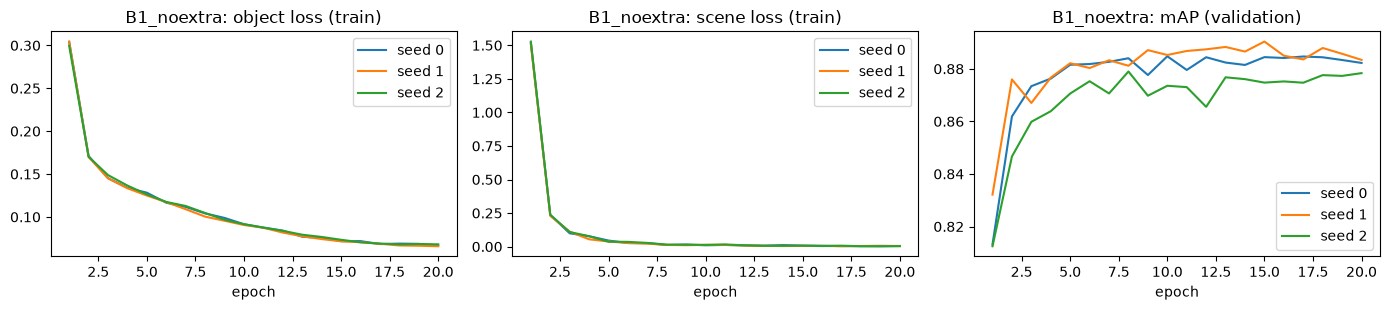

In [3]:
plot_history("B1_noextra")

## 3. B1_shuffled – same images as B1, random scene labels

The run prints the share of training images whose scene label stayed the same after shuffling (about 1/30 is
expected by chance). Random labels cannot be predicted from the images, so the scene loss can only go down by
memorizing the training images (about 47 minutes per seed).

In [4]:
run_all("B1_shuffled", SEEDS, data, CONFIG, device)

B1_shuffled_seed0 already done, skipped
B1_shuffled_seed1 already done, skipped
B1_shuffled_seed2 already done, skipped


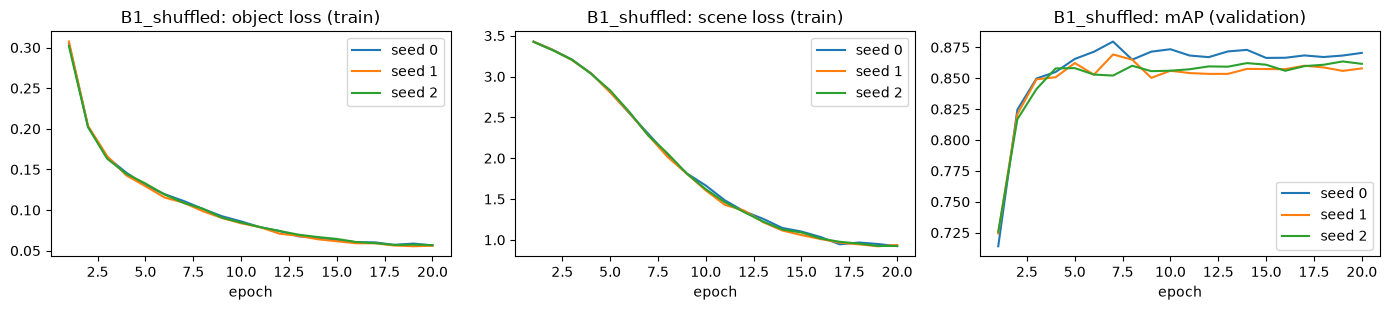

In [5]:
plot_history("B1_shuffled")

## 4. B0_long – B0 trained as long as B1

One B1 epoch contains the 2,160 multi-label images and 2,160 scene-only images, so in 20 epochs B1 sees
86,400 images. B0_long is B0 trained for 40 epochs, which also gives 86,400 images. If B0_long is not better
than B0, the gain of B1 does not come from the longer training (about 55 minutes per seed).

In [6]:
run_all("B0_long", SEEDS, data, CONFIG, device)

B0_long_seed0 already done, skipped
B0_long_seed1 already done, skipped
B0_long_seed2 already done, skipped


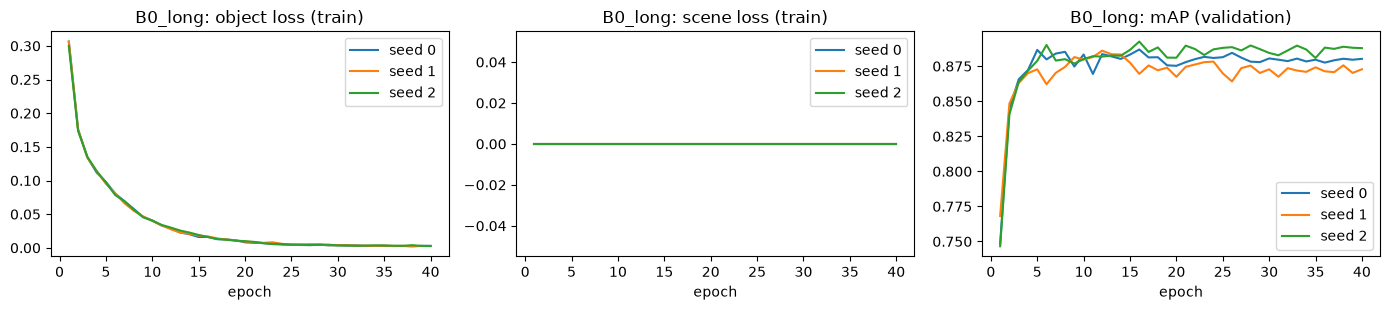

In [7]:
plot_history("B0_long")

## 5. B0_reg – B0 with stronger regularization

B0 overfits: its training loss goes almost to zero while the validation mAP stops improving. A second task is
also a form of regularization, so part of the gain of B1 could come from regularization alone. B0_reg trains B0
with two standard regularizers for multi-label classification:

- **mixup** (α = 0.2): each training image is blended with another image of the batch,
  x = λ·x₁ + (1 − λ)·x₂ with λ ~ Beta(0.2, 0.2), and the labels are blended with the same λ;
- **label smoothing** (ε = 0.1): the targets 0 and 1 become 0.05 and 0.95.

If B0_reg reaches B1, the gain of B1 can be explained by regularization; if not, the scene labels add
information (about 27 minutes per seed).

In [8]:
run_all("B0_reg", SEEDS, data, CONFIG, device)

--- B0_reg_seed0 ---


/Users/yagizcetin/Documents/Github/CS415-CourseProject/aidml.py:223: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:212.)
  scenes = torch.from_numpy(data["scenes"])


epoch  1 | object loss 0.4113 | scene loss 0.0000 | val mAP 0.7626 | 61 s
epoch  2 | object loss 0.3399 | scene loss 0.0000 | val mAP 0.8464 | 57 s
epoch  3 | object loss 0.3206 | scene loss 0.0000 | val mAP 0.8621 | 59 s
epoch  4 | object loss 0.3217 | scene loss 0.0000 | val mAP 0.8695 | 58 s
epoch  5 | object loss 0.3097 | scene loss 0.0000 | val mAP 0.8754 | 63 s
epoch  6 | object loss 0.3035 | scene loss 0.0000 | val mAP 0.8724 | 64 s
epoch  7 | object loss 0.2957 | scene loss 0.0000 | val mAP 0.8806 | 61 s
epoch  8 | object loss 0.2905 | scene loss 0.0000 | val mAP 0.8855 | 66 s
epoch  9 | object loss 0.2843 | scene loss 0.0000 | val mAP 0.8878 | 65 s
epoch 10 | object loss 0.2737 | scene loss 0.0000 | val mAP 0.8734 | 65 s
epoch 11 | object loss 0.2763 | scene loss 0.0000 | val mAP 0.8836 | 65 s
epoch 12 | object loss 0.2681 | scene loss 0.0000 | val mAP 0.8852 | 65 s
epoch 13 | object loss 0.2907 | scene loss 0.0000 | val mAP 0.8892 | 64 s
epoch 14 | object loss 0.2847 | scene 

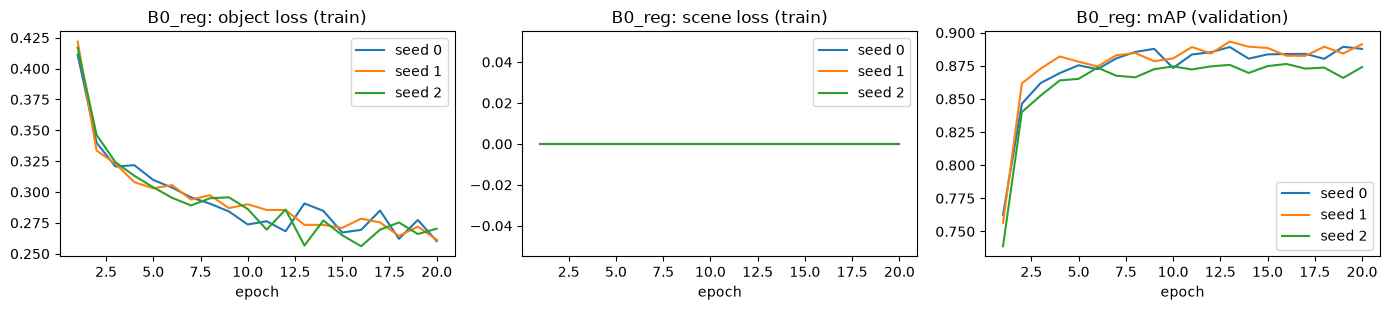

In [9]:
plot_history("B0_reg")